# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: De Casa, Samantha Claire E.
- _Student No._: 2023-15141
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure
![Description](Minimization.png)

Figures 1.1 and 1.2 show the plots of $\phi(x)$ and $f(x)$, while Figures 2.1 and 2.2 illustrate the graph of their first derivatives, $\phi^\prime(x)$ and $f^\prime(x)$. Figures 1.1 and 1.2 also reveal the local extrema (minima and maxima) of $\phi(x)$ and $f(x)$ obtained by using the golden-section search method, whereas Figures 2.1 and 2.2 present the relative extrema of these functions as roots of their first derivatives.

---

### Report discussion
As can be seen on the figures above, the local extrema of $\phi(x)$ and $f(x)$ found by using the global-section search method are not all exactly equal to the points obtained by plotting the first derivatives of these functions. The plot of $\phi(x)$ (see Figure 1.1) reveals that there exists a local maximum at $x=2$, a local minimum at $x=4$, and another local minimum roughly at $x=1$ (precisely at $x=0.75$ as observed in Figure 2.1). The results of the golden-section search method confirm that $x=0.75$ and $x=4$ are local minimum points, but the relative maximum point obtained, $x\approx 2.5$, is greater than the theoretical value $x=2$ presented at Figure 2.1. 

It also apparent on the plot of $f(x)$ (see Figure 1.2) that there exists a local maximum at $x=2$, a local minimum roughly at $x=-1$ (precisely at $x =-0.679862$ as observed in Figure 2.2), and another local minimum at $x=4$ (precisely at $x = 4.103325$ as observed in Figure 2.2). While the golden-section search method verifies the existence of a local minimum at $x\approx 4$, the other relative extrema points, $x\approx 0.5$ and $x\approx 2.5$, significantly deviate from the theoretical values presented at Figure 2.2. 

The difference between the results of the golden-section search method and the analytical derivative approach stems from finite convergence tolerance and floating-point precision limits. While the analytical derivative provides the exact theoretical location of a relative extremum, the golden-section search is an iterative numerical approximation that is subject to limitations. If a number other than the golden ratio is used to perform the golden-section search algorithm, the algorithm will not automatically fail, but its efficiency and convergence can change. The golden ratio is optimal because it makes the remaining interval geometrically similar to the original interval, allowing one of the old interior points to be reused at every iteration.

---

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [2]:
def phi(x): # equation 5.91
    return x**4 - 9*(x**3) + 25*(x**2) - 24*x + 4

def f(x): # equation 5.145
    return -(x**5) + 4*(x**4) - 4*(x**3) + (x**2)*(np.exp(x)) - 2*(x**2) - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

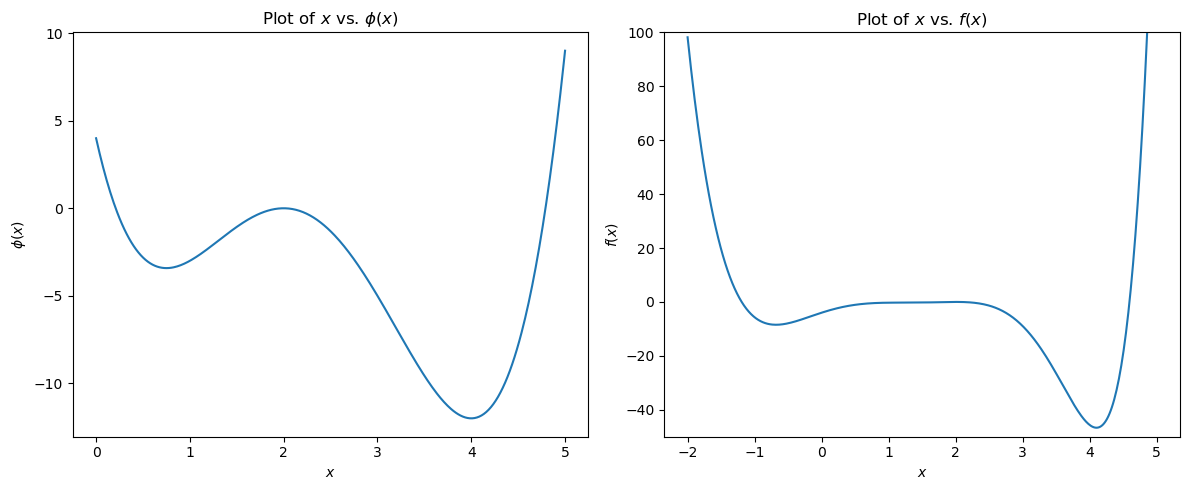

In [3]:
xp = np.linspace(0, 5, 400) # x-values of phi(x) 
yp = phi(xp)

xf = np.linspace(-2, 5, 400) # x-values of f(x)
yf = f(xf)

fig, axs = plt.subplots(1, 2, figsize = (12, 5))

axs[0].plot(xp, yp, label = r"$\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4$")
axs[0].set_title(r"Plot of $x$ vs. $\phi(x)$")
axs[0].set_xlabel(r"$x$")
axs[0].set_ylabel(r"$\phi(x)$")

axs[1].plot(xf, yf, label = r"$f(x) = -x^5 + 4x^4 - 4x^3 + x^2e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8$")
axs[1].set_title(r"Plot of $x$ vs. $f(x)$")
axs[1].set_xlabel(r"$x$")
axs[1].set_ylabel(r"$f(x)$")
axs[1].set_ylim(-50, 100)

plt.tight_layout()
plt.show()

### Rough estimate of the local minima and maxima

It is evident on the plot of $\phi(x)$ that there exists a local maximum at $x=2$ and local minima at $x=4$ and roughly at $x=1$. It is also apparent on the plot of $f(x)$ that there exists a local minimum roughly at $x=-1$ and at $x=4$. The local maximum, on the other hand, is imperceptible on this plot althought it exists.

---

In [4]:
def golsearch(g, x0, x1, itermax=400, tol=1.e-10):
    golratio = (1 + sqrt(5))/2 # golden ratio
    for i in range(1, itermax):
        x2 = x0 + (x1 - x0)/(golratio + 1)
        x3 = x0 + ((x1 - x0)*golratio)/(golratio + 1)

        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3

        x = (x0 + x1)/2
        if abs(x1 - x0) < tol:
            break
    else:
        x = None
    return x

In [5]:
# Local extrema points of phi(x)
x1p = golsearch(phi, 0, 1.5)
x2p = golsearch(phi, 1.5, 2.5)
x3p = golsearch(phi, 2.5, 4)

print(x1p, x2p, x3p)

0.7500000050343727 2.4999999999534883 3.999999937918476


In [6]:
# Local extrema points of f(x)
x1f = golsearch(f, -1.5, 0.5)
x2f = golsearch(f, 1.5, 2.5)
x3f = golsearch(f, 3, 5)

print(x1f, x2f, x3f)

0.49999999996446814 2.4999999999534883 3.999999999083336


In [7]:
def derivative_phi(x): # derivative of equation 5.91
    return 4*(x**3) - 27*(x**2) + 50*x - 24

def derivative_f(x): # derivative of equation 5.145
    return -5*(x**4) + 16*(x**3) - 12*(x**2) + 2*x*np.exp(x) + (x**2)*np.exp(x) - 4*x - 4*np.exp(x) - 4*x*np.exp(x) + 8 + 4*np.exp(x)

#the roots of these derivatives (by solving analytically) are:
roots_dphi = [0.75, 2, 4]
roots_df = [-0.679862, 2, 4.103325]

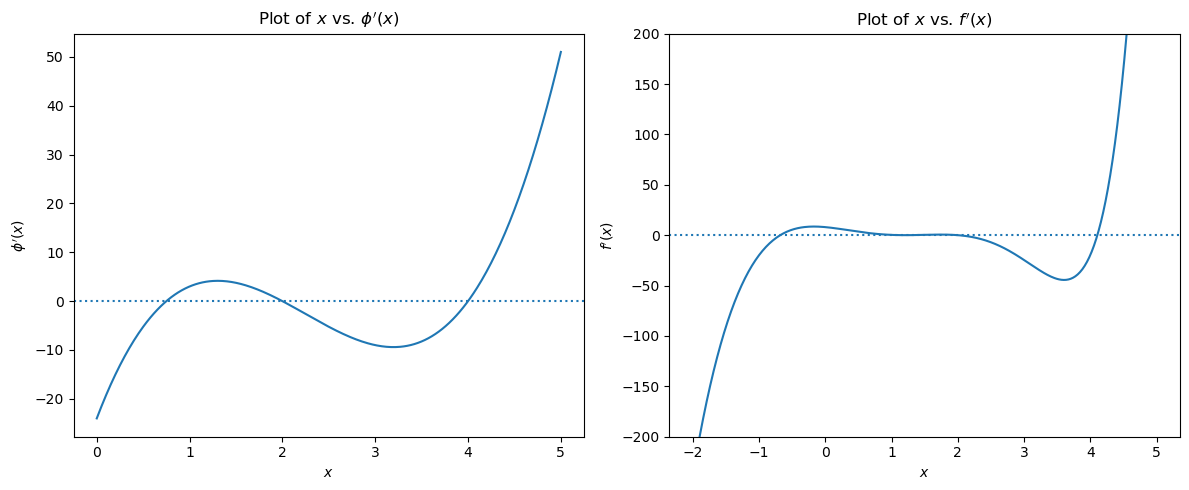

In [8]:
xp = np.linspace(0, 5, 400)
ydp = derivative_phi(xp)

xf = np.linspace(-2, 5, 400)
ydf = derivative_f(xf)

fig, axs = plt.subplots(1, 2, figsize = (12, 5))

axs[0].plot(xp, ydp)
axs[0].set_title(r"Plot of $x$ vs. $\phi^\prime(x)$")
axs[0].set_xlabel(r"$x$")
axs[0].set_ylabel(r"$\phi^\prime(x)$")
axs[0].axhline(0, linestyle = ":")

axs[1].plot(xf, ydf)
axs[1].set_title(r"Plot of $x$ vs. $f^\prime(x)$")
axs[1].set_xlabel(r"$x$")
axs[1].set_ylabel(r"$f^\prime(x)$")
axs[1].set_ylim(-200, 200)
axs[1].axhline(0, linestyle = ":")

plt.tight_layout()
plt.show()

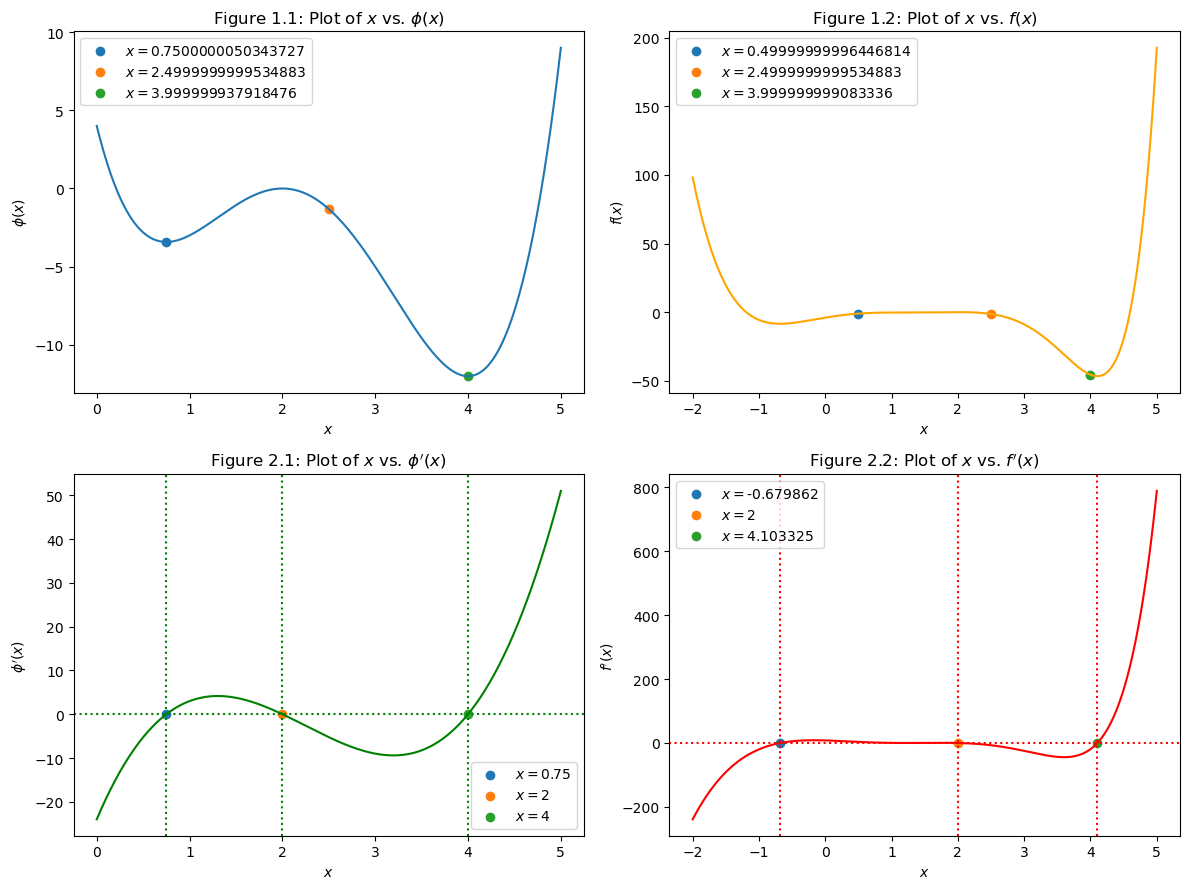

In [10]:
xps = [x1p, x2p, x3p]
xfs = [x1f, x2f, x3f]

fig, axs = plt.subplots(2, 2, figsize = (12, 9))

axs[0, 0].plot(xp, yp)
for x in xps:
    axs[0, 0].scatter(x, phi(x), marker="o", label = r"$x = $" + str(x))
axs[0, 0].set_title(r"Figure 1.1: Plot of $x$ vs. $\phi(x)$")
axs[0, 0].set_xlabel(r"$x$")
axs[0, 0].set_ylabel(r"$\phi(x)$")
axs[0, 0].legend()

axs[0, 1].plot(xf, yf, color = "orange")
for x in xfs:
    axs[0, 1].scatter(x, f(x), marker="o", label = r"$x = $" + str(x))
axs[0, 1].set_title(r"Figure 1.2: Plot of $x$ vs. $f(x)$")
axs[0, 1].set_xlabel(r"$x$")
axs[0, 1].set_ylabel(r"$f(x)$")
axs[0, 1].legend()

axs[1, 0].plot(xp, ydp, color = "green")
axs[1, 0].set_title(r"Figure 2.1: Plot of $x$ vs. $\phi^\prime(x)$")
axs[1, 0].set_xlabel(r"$x$")
axs[1, 0].set_ylabel(r"$\phi^\prime(x)$")
axs[1, 0].axhline(0, linestyle = ":", color = "green")
for x in roots_dphi:
    axs[1, 0].axvline(x, linestyle = ":", color = "green")
    axs[1, 0].scatter(x, derivative_phi(x), marker="o", label = r"$x = $" + str(x))
axs[1, 0].legend()

axs[1, 1].plot(xf, ydf, color = "red")
axs[1, 1].set_title(r"Figure 2.2: Plot of $x$ vs. $f^\prime(x)$")
axs[1, 1].set_xlabel(r"$x$")
axs[1, 1].set_ylabel(r"$f^\prime(x)$")
axs[1, 1].axhline(0, linestyle = ":", color = "red")
for x in roots_df:
    axs[1, 1].axvline(x, linestyle = ":", color = "red")
    axs[1, 1].scatter(x, derivative_f(x), marker="o", label = r"$x = $" + str(x))
axs[1, 1].legend()

plt.tight_layout()
plt.show()
fig.savefig("Minimization.png")

#### Problem 1 code summary
The purpose of this algorithm is to locate the local extrema (minima and maxima) of $\phi(x)$ and $f(x)$ using the golden-section search method. The script is straightforward, and was written in reference to Code 5.6 of Alex Gezerlis' *Numerical Methods in Physics with Python (2nd Edition)* with some minor adjustments.

---